# Лабораторная работа №1. Моделирование случайной величины с произвольным законом распределения

**Вариант:** номер по журналу — 11, группа — 2, ПК — 4.

| Параметр | Значение | Откуда |
|---|---|---|
| σ | 2 | номер группы |
| μ = a = λ | 11 | номер по журналу |
| Вариант задания | 3 (11 → 3 по кругу из 8) | закон x — **нормальный**, закон y — **показательный** |

**Цель работы:** отработать методы получения случайных величин (СВ), распределённых по закону с заданными параметрами, и методы анализа случайных процессов.

План работы:
1. Формирование равномерно распределённой СВ: библиотечной функцией и конгруэнтным генератором.
2. Формирование нормальной СВ $N(\mu=11,\ \sigma=2)$ из равномерной СВ (произведение релеевской и арксинусной СВ).
3. Формирование показательной СВ $y$ с параметром $\lambda = 11$ из нормальных СВ $x$.

In [1]:
%matplotlib inline
import numpy as np
from numpy.random import default_rng
from scipy import stats
import matplotlib.pyplot as plt
from scheme import draw_scheme

plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})

# Параметры варианта
sigma_param = 2      # σ — номер группы
mu_param = 11        # μ — номер по журналу
lambda_param = 11    # λ — номер по журналу
n_values = 20000     # объём выборки
n_bins = 40          # число интервалов гистограмм

rng = default_rng(11)

## Вспомогательные функции

Нормировка гистограммы выполняется так, чтобы она стала оценкой плотности вероятности:

$$\hat W(x_k) = \frac{n_k}{N\,\Delta x},$$

где $n_k$ — число значений, попавших в $k$-й интервал, $N$ — объём выборки, $\Delta x$ — ширина интервала.
После этой нормировки площадь под гистограммой равна 1: $\sum_k \hat W(x_k)\,\Delta x = \sum_k n_k / N = 1$.
Это то же самое, что `density=True` в matplotlib или `'Normalization','pdf'` в `histcounts` MATLAB.
Аналитическая плотность вычисляется в серединах интервалов гистограммы.

In [2]:
def hist_pdf(data, edges):
    """Гистограмма, нормированная на объём выборки и ширину интервала (оценка ПВ)."""
    counts, _ = np.histogram(data, bins=edges)
    widths = np.diff(edges)
    return counts / (len(data) * widths)


def pdf_compare(samples, labels, edges, pdf=None, pdf_label='Аналитическая ПВ',
                title='', xlabel='x', ylabel='W(x)', ax=None):
    """Нормированные гистограммы нескольких выборок и аналитическая ПВ в одной СК."""
    if ax is None:
        _, ax = plt.subplots()
    centers = (edges[:-1] + edges[1:]) / 2
    for s, lab in zip(samples, labels):
        w = hist_pdf(s, edges)
        ax.stairs(w, edges, fill=True, alpha=0.35, label=lab)
        ax.stairs(w, edges, lw=1.2)
    if pdf is not None:
        ax.plot(centers, pdf(centers), 'r.-', lw=1.8, label=pdf_label)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    return ax


def realization(samples, labels, limit=200, title='Реализация', ax=None):
    if ax is None:
        _, ax = plt.subplots()
    for s, lab in zip(samples, labels):
        ax.plot(s[:limit], lw=1, label=lab)
    ax.set(title=title, xlabel='Номер отсчёта k', ylabel='Значение')
    ax.legend()
    return ax


def describe(name, data, mean_theory, var_theory):
    print(f'{name:28s} M = {np.mean(data):8.4f} (теор. {mean_theory:8.4f}),  '
          f'D = {np.var(data):8.4f} (теор. {var_theory:8.4f})')

## 1. Равномерно распределённая СВ

### 1.1 Конгруэнтный генератор

Линейный конгруэнтный генератор рекуррентно формирует целые числа

$$z_{k+1} = (A\,z_k + C) \bmod M, \qquad u_k = z_k / M \in [0;\,1),$$

где $z_0$ — начальное значение (seed). Последовательность периодическая, её период не больше $M$.
Используются параметры $A = 1103515245$, $C = 12345$, $M = 2^{31}$ (генератор `rand()` из стандартной библиотеки C).
Для сравнения ниже показан генератор с малыми параметрами $A=5,\ C=3,\ M=32$: у него период всего 32 значения.

In [3]:
def lcg(n, seed=1, A=1103515245, C=12345, M=2**31):
    """Линейный конгруэнтный генератор: n равномерных СВ на [0; 1)."""
    z = seed
    out = np.empty(n)
    for k in range(n):
        z = (A * z + C) % M
        out[k] = z / M
    return out


u_lcg = lcg(n_values, seed=2024)                 # собственный генератор
u_lib = rng.uniform(0, 1, n_values)              # библиотечная функция numpy

# Генератор с малыми параметрами: последовательность повторяется
u_bad = lcg(100, seed=7, A=5, C=3, M=32)
period = np.argmax(u_bad[1:] == u_bad[0]) + 1
print('Период генератора с A=5, C=3, M=32:', period)

describe('Равномерная (конгруэнтный)', u_lcg, 0.5, 1/12)
describe('Равномерная (numpy)', u_lib, 0.5, 1/12)

Период генератора с A=5, C=3, M=32: 32
Равномерная (конгруэнтный)   M =   0.5006 (теор.   0.5000),  D =   0.0831 (теор.   0.0833)
Равномерная (numpy)          M =   0.4969 (теор.   0.5000),  D =   0.0833 (теор.   0.0833)


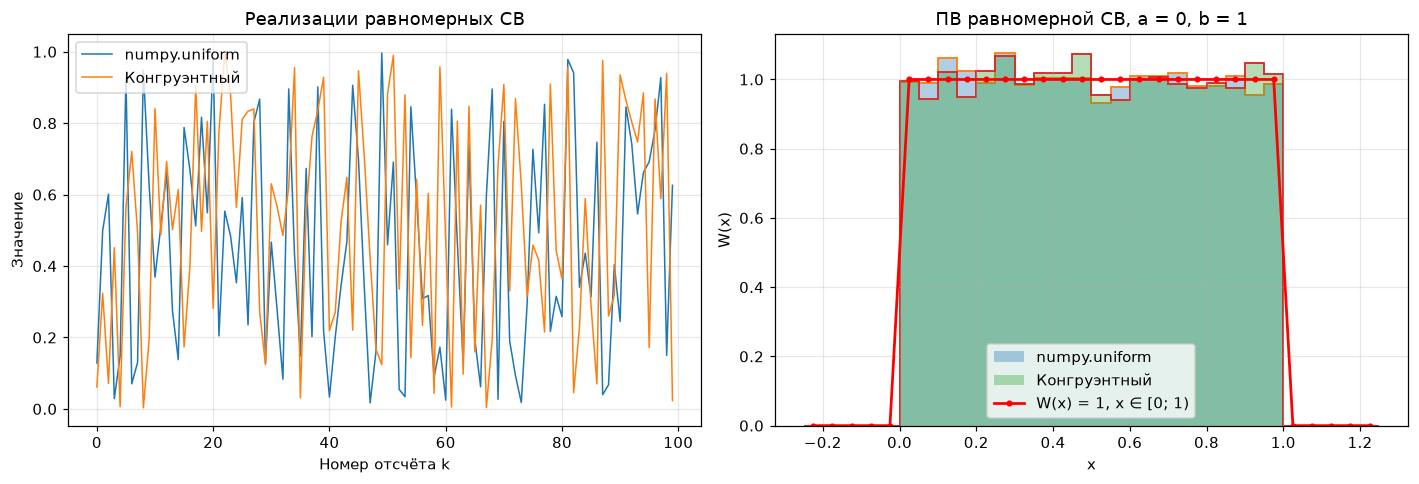

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
realization([u_lib, u_lcg], ['numpy.uniform', 'Конгруэнтный'], limit=100,
            title='Реализации равномерных СВ', ax=axs[0])
edges_u = np.linspace(-0.25, 1.25, 31)
pdf_compare([u_lib, u_lcg], ['numpy.uniform', 'Конгруэнтный'], edges_u,
            pdf=lambda x: stats.uniform.pdf(x, 0, 1),
            pdf_label='W(x) = 1, x ∈ [0; 1)',
            title='ПВ равномерной СВ, a = 0, b = 1', xlabel='x', ylabel='W(x)', ax=axs[1])
plt.tight_layout()

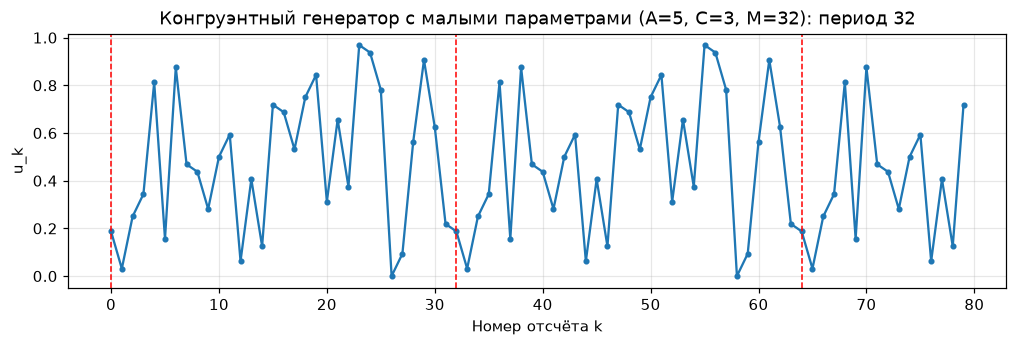

In [5]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(u_bad[:80], '.-')
ax.set(title='Конгруэнтный генератор с малыми параметрами (A=5, C=3, M=32): период 32',
       xlabel='Номер отсчёта k', ylabel='u_k')
for k in range(0, 80, 32):
    ax.axvline(k, color='r', ls='--', lw=1)

## 2. Нормальная СВ из равномерной

### 2.1 Математические выкладки

Пусть $u_1, u_2$ — независимые СВ, равномерные на $[0;1)$.

**Релеевская СВ** (метод обратной функции). Функция распределения Рэлея при $\sigma=1$: $F(r) = 1 - e^{-r^2/2}$.
Решая $F(r) = 1-u$ (СВ $1-u$ тоже равномерна), получаем
$$r = \sqrt{-2\ln u_1}, \qquad W(r) = r\,e^{-r^2/2},\ r \ge 0.$$

**Арксинусная СВ.** Синус равномерно распределённой фазы $\varphi = 2\pi u_2$:
$$s = \sin(2\pi u_2), \qquad W(s) = \frac{1}{\pi\sqrt{1-s^2}},\ |s|<1.$$

**Нормальная СВ** (преобразование Бокса — Мюллера). Пара $(r, \varphi)$ — полярные координаты точки с независимыми нормальными декартовыми координатами,
поэтому $\xi = r\sin\varphi \sim N(0, 1)$. Затем задаются СКО и математическое ожидание:
$$y = \sigma\,\sqrt{-2\ln u_1}\,\sin(2\pi u_2) + \mu, \qquad W(y) = \frac{1}{\sigma\sqrt{2\pi}}\,e^{-\frac{(y-\mu)^2}{2\sigma^2}}.$$

Вторая независимая нормальная СВ получается так же через $\cos(2\pi u_2)$.

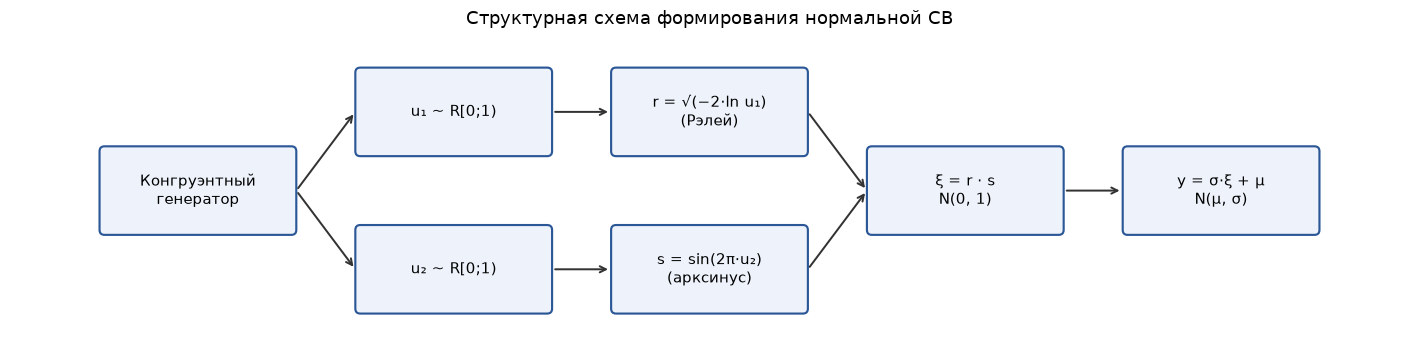

In [6]:
draw_scheme(
    blocks={
        'g':  (0, 0, 'Конгруэнтный\nгенератор'),
        'u1': (2.6, 0.8, 'u₁ ~ R[0;1)'),
        'u2': (2.6, -0.8, 'u₂ ~ R[0;1)'),
        'r':  (5.2, 0.8, 'r = √(−2·ln u₁)\n(Рэлей)'),
        's':  (5.2, -0.8, 's = sin(2π·u₂)\n(арксинус)'),
        'm':  (7.8, 0, 'ξ = r · s\nN(0, 1)'),
        'y':  (10.4, 0, 'y = σ·ξ + μ\nN(μ, σ)'),
    },
    arrows=[('g', 'u1', ''), ('g', 'u2', ''), ('u1', 'r', ''), ('u2', 's', ''),
            ('r', 'm', ''), ('s', 'm', ''), ('m', 'y', '')],
    title='Структурная схема формирования нормальной СВ', size=(13, 3.6));

In [7]:
# Исходные равномерные СВ из собственного генератора (две независимые половины последовательности)
u_all = lcg(2 * n_values, seed=12345)
u_1, u_2 = u_all[:n_values], u_all[n_values:]

r_ray = np.sqrt(-2 * np.log(1 - u_1))   # Рэлей (1-u вместо u: исключает log(0), u ∈ [0;1))
s_arc = np.sin(2 * np.pi * u_2)          # арксинус
y_custom = sigma_param * r_ray * s_arc + mu_param   # нормальная N(μ, σ)

y_lib = rng.normal(loc=mu_param, scale=sigma_param, size=n_values)   # встроенная функция

describe('Нормальная (реализованная)', y_custom, mu_param, sigma_param**2)
describe('Нормальная (numpy.normal)', y_lib, mu_param, sigma_param**2)

Нормальная (реализованная)   M =  11.0126 (теор.  11.0000),  D =   3.9412 (теор.   4.0000)
Нормальная (numpy.normal)    M =  10.9954 (теор.  11.0000),  D =   4.0012 (теор.   4.0000)


### 2.2 Исходное распределение, функции преобразования и промежуточные СВ

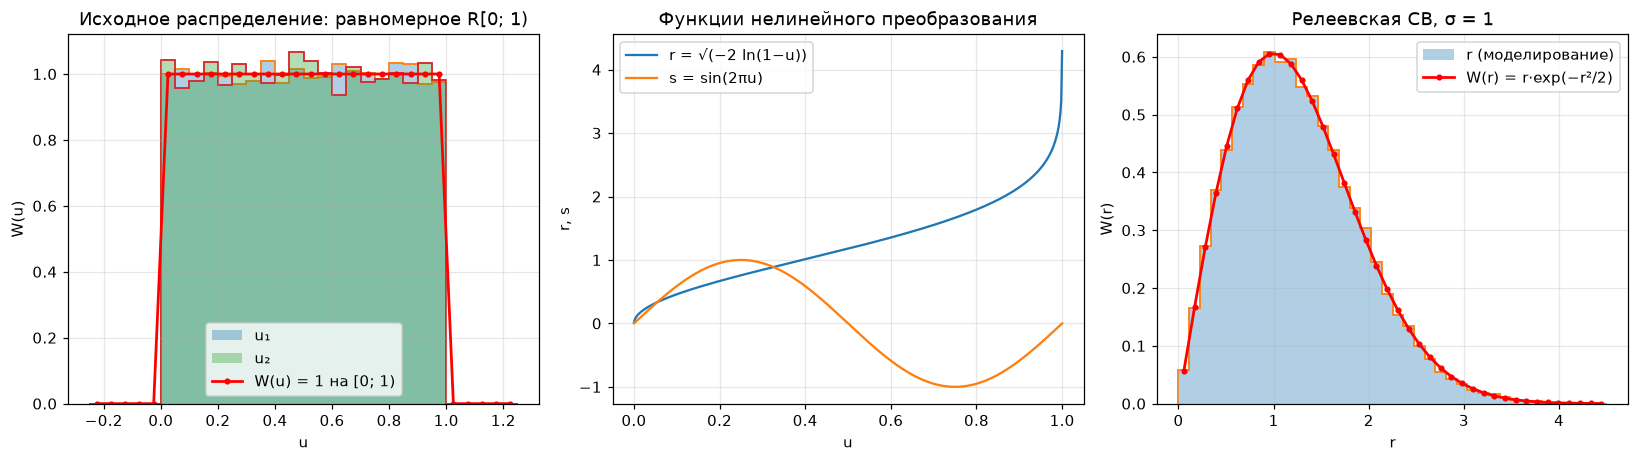

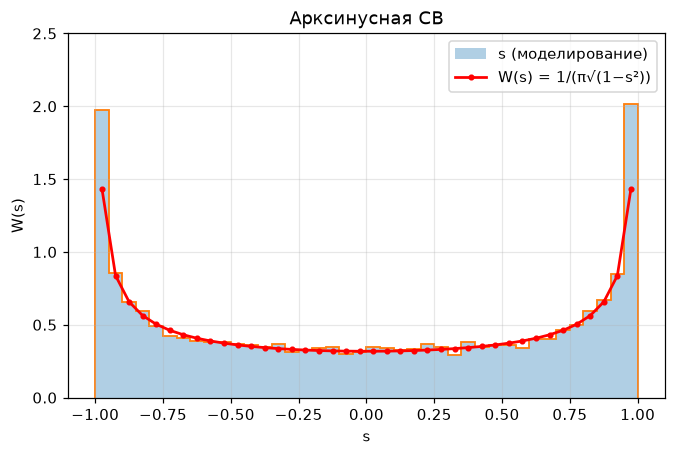

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
pdf_compare([u_1, u_2], ['u₁', 'u₂'], edges_u, pdf=lambda x: stats.uniform.pdf(x),
            pdf_label='W(u) = 1 на [0; 1)', title='Исходное распределение: равномерное R[0; 1)',
            xlabel='u', ylabel='W(u)', ax=axs[0])

uu = np.linspace(1e-4, 1 - 1e-4, 500)
axs[1].plot(uu, np.sqrt(-2 * np.log(1 - uu)), label='r = √(−2 ln(1−u))')
axs[1].plot(uu, np.sin(2 * np.pi * uu), label='s = sin(2πu)')
axs[1].set(title='Функции нелинейного преобразования', xlabel='u', ylabel='r, s')
axs[1].legend()

edges_r = np.linspace(0, 4.5, 41)
pdf_compare([r_ray], ['r (моделирование)'], edges_r,
            pdf=lambda x: stats.rayleigh.pdf(x), pdf_label='W(r) = r·exp(−r²/2)',
            title='Релеевская СВ, σ = 1', xlabel='r', ylabel='W(r)', ax=axs[2])
plt.tight_layout()

fig, ax = plt.subplots(figsize=(7, 4.3))
edges_s = np.linspace(-1, 1, 41)
pdf_compare([s_arc], ['s (моделирование)'], edges_s,
            pdf=lambda x: 1 / (np.pi * np.sqrt(1 - x**2)), pdf_label='W(s) = 1/(π√(1−s²))',
            title='Арксинусная СВ', xlabel='s', ylabel='W(s)', ax=ax)
ax.set_ylim(0, 2.5);

### 2.3 Результат: нормальная СВ $N(\mu = 11,\ \sigma = 2)$

Критерий Колмогорова — Смирнова для реализованного алгоритма: D = 0.0054, p = 0.592


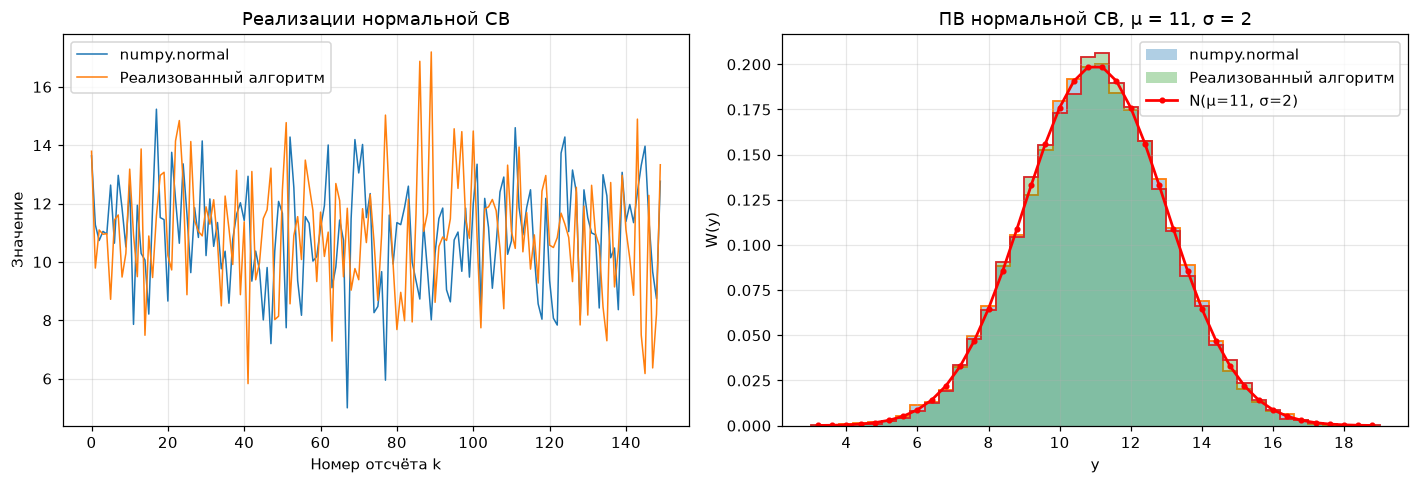

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
realization([y_lib, y_custom], ['numpy.normal', 'Реализованный алгоритм'], limit=150,
            title='Реализации нормальной СВ', ax=axs[0])
edges_n = np.linspace(mu_param - 4 * sigma_param, mu_param + 4 * sigma_param, n_bins + 1)
pdf_compare([y_lib, y_custom], ['numpy.normal', 'Реализованный алгоритм'], edges_n,
            pdf=lambda x: stats.norm.pdf(x, mu_param, sigma_param),
            pdf_label=f'N(μ={mu_param}, σ={sigma_param})',
            title=f'ПВ нормальной СВ, μ = {mu_param}, σ = {sigma_param}',
            xlabel='y', ylabel='W(y)', ax=axs[1])
plt.tight_layout()

ks = stats.kstest(y_custom, lambda v: stats.norm.cdf(v, mu_param, sigma_param))
print(f'Критерий Колмогорова — Смирнова для реализованного алгоритма: D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}')

## 3. Вариант 3: показательная СВ $y$ из нормальных СВ $x$

### 3.1 Математические выкладки

Исходная СВ — нормальная с нулевым средним и СКО $\sigma = 2$: $x_1, x_2 \sim N(0, \sigma)$, независимые.
Математическое ожидание исходных СВ берётся равным нулю: иначе сумма квадратов даёт нецентральное распределение и показательный закон не получится.

1. Нормированная сумма квадратов двух независимых стандартных нормальных СВ распределена по закону хи-квадрат с двумя степенями свободы:
$$q = \frac{x_1^2 + x_2^2}{\sigma^2} \sim \chi^2_2, \qquad W(q) = \tfrac12 e^{-q/2},$$
то есть это показательное распределение со средним 2.
2. Масштабирование $y = \dfrac{q}{2\lambda}$ даёт $P(y<t) = P(q < 2\lambda t) = 1 - e^{-\lambda t}$, то есть показательный закон с параметром $\lambda$.

Итоговое преобразование:
$$\boxed{\,y = \frac{x_1^2 + x_2^2}{2\,\sigma^2\,\lambda}\,}, \qquad W(y) = \lambda\,e^{-\lambda y},\ y \ge 0; \qquad M\{y\} = \frac1\lambda = 0{,}0909,\quad D\{y\} = \frac{1}{\lambda^2} = 0{,}00826.$$

Физический смысл: $\sqrt{x_1^2 + x_2^2}$ — огибающая узкополосного гауссовского шума (закон Рэлея), а $x_1^2 + x_2^2$ — его мгновенная мощность (показательный закон).

Нормальные СВ $x_1, x_2$ формируются реализованным выше алгоритмом (конгруэнтный генератор → Бокс — Мюллер, синусная и косинусная ветви).
Для сравнения используются встроенные функции `numpy.random.exponential` и `scipy.stats.expon`.

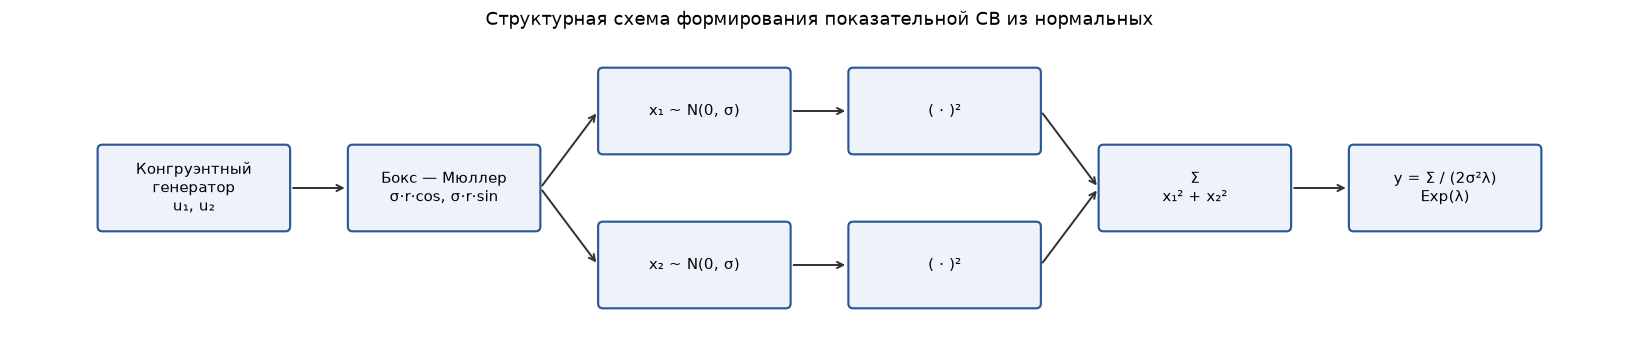

In [10]:
draw_scheme(
    blocks={
        'g':  (0, 0, 'Конгруэнтный\nгенератор\nu₁, u₂'),
        'bm': (2.6, 0, 'Бокс — Мюллер\nσ·r·cos, σ·r·sin'),
        'x1': (5.2, 0.8, 'x₁ ~ N(0, σ)'),
        'x2': (5.2, -0.8, 'x₂ ~ N(0, σ)'),
        'q1': (7.8, 0.8, '( · )²'),
        'q2': (7.8, -0.8, '( · )²'),
        's':  (10.4, 0, 'Σ\nx₁² + x₂²'),
        'y':  (13.0, 0, 'y = Σ / (2σ²λ)\nExp(λ)'),
    },
    arrows=[('g', 'bm', ''), ('bm', 'x1', ''), ('bm', 'x2', ''), ('x1', 'q1', ''), ('x2', 'q2', ''),
            ('q1', 's', ''), ('q2', 's', ''), ('s', 'y', '')],
    title='Структурная схема формирования показательной СВ из нормальных', size=(15, 3.6));

In [11]:
# Исходные нормальные СВ x ~ N(0, σ) — реализованным алгоритмом
u_all = lcg(2 * n_values, seed=777)
r_ray = np.sqrt(-2 * np.log(1 - u_all[:n_values]))
phi = 2 * np.pi * u_all[n_values:]
x_1 = sigma_param * r_ray * np.cos(phi)
x_2 = sigma_param * r_ray * np.sin(phi)

# Нелинейное преобразование в показательную СВ
y_exp_custom = (x_1**2 + x_2**2) / (2 * sigma_param**2 * lambda_param)

# Встроенные функции
y_exp_np = rng.exponential(scale=1 / lambda_param, size=n_values)
y_exp_sp = stats.expon.rvs(scale=1 / lambda_param, size=n_values, random_state=11)

describe('x₁ (нормальная)', x_1, 0, sigma_param**2)
describe('x₂ (нормальная)', x_2, 0, sigma_param**2)
print(f'Коэффициент корреляции x₁ и x₂: {np.corrcoef(x_1, x_2)[0, 1]:.4f}')
describe('Показательная (реализ.)', y_exp_custom, 1 / lambda_param, 1 / lambda_param**2)
describe('Показательная (numpy)', y_exp_np, 1 / lambda_param, 1 / lambda_param**2)
describe('Показательная (scipy)', y_exp_sp, 1 / lambda_param, 1 / lambda_param**2)

x₁ (нормальная)              M =  -0.0004 (теор.   0.0000),  D =   4.0527 (теор.   4.0000)
x₂ (нормальная)              M =   0.0257 (теор.   0.0000),  D =   4.0061 (теор.   4.0000)
Коэффициент корреляции x₁ и x₂: 0.0057
Показательная (реализ.)      M =   0.0916 (теор.   0.0909),  D =   0.0084 (теор.   0.0083)
Показательная (numpy)        M =   0.0905 (теор.   0.0909),  D =   0.0083 (теор.   0.0083)
Показательная (scipy)        M =   0.0904 (теор.   0.0909),  D =   0.0082 (теор.   0.0083)


### 3.2 Исходное распределение $W(x)$ и функция преобразования

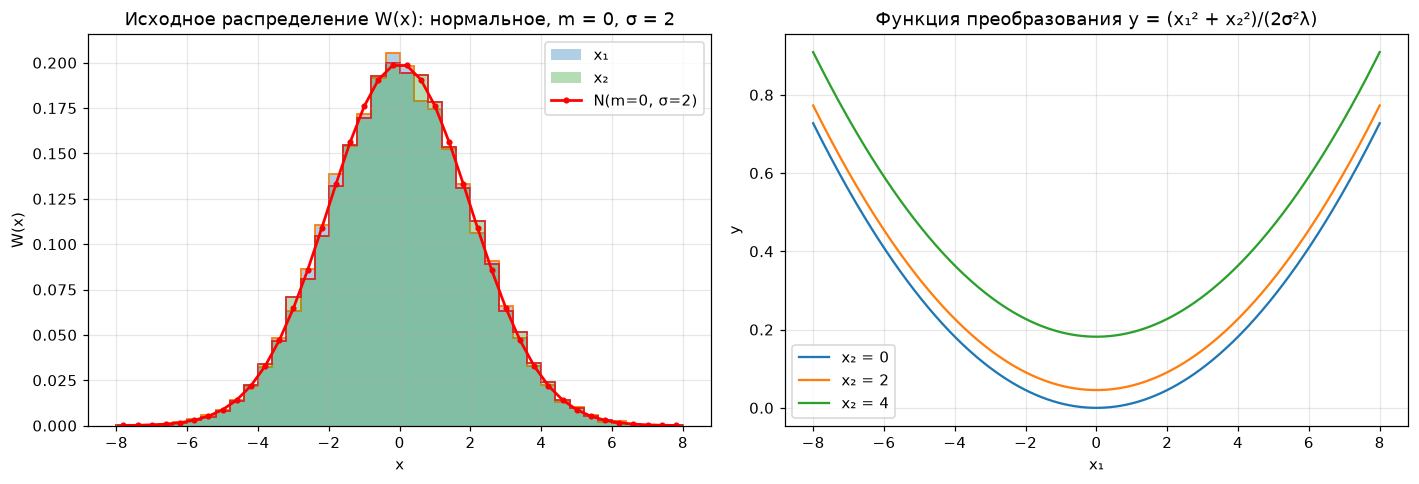

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
edges_x = np.linspace(-4 * sigma_param, 4 * sigma_param, n_bins + 1)
pdf_compare([x_1, x_2], ['x₁', 'x₂'], edges_x,
            pdf=lambda x: stats.norm.pdf(x, 0, sigma_param),
            pdf_label=f'N(m=0, σ={sigma_param})',
            title=f'Исходное распределение W(x): нормальное, m = 0, σ = {sigma_param}',
            xlabel='x', ylabel='W(x)', ax=axs[0])

# Функция преобразования при x₂ = const (сечения поверхности y(x₁, x₂))
xx = np.linspace(-4 * sigma_param, 4 * sigma_param, 400)
for x2c in [0, sigma_param, 2 * sigma_param]:
    axs[1].plot(xx, (xx**2 + x2c**2) / (2 * sigma_param**2 * lambda_param), label=f'x₂ = {x2c}')
axs[1].set(title='Функция преобразования y = (x₁² + x₂²)/(2σ²λ)', xlabel='x₁', ylabel='y')
axs[1].legend()
plt.tight_layout()

### 3.3 Результат: показательная СВ, $\lambda = 11$

Критерий Колмогорова — Смирнова для реализованного алгоритма: D = 0.0057, p = 0.522


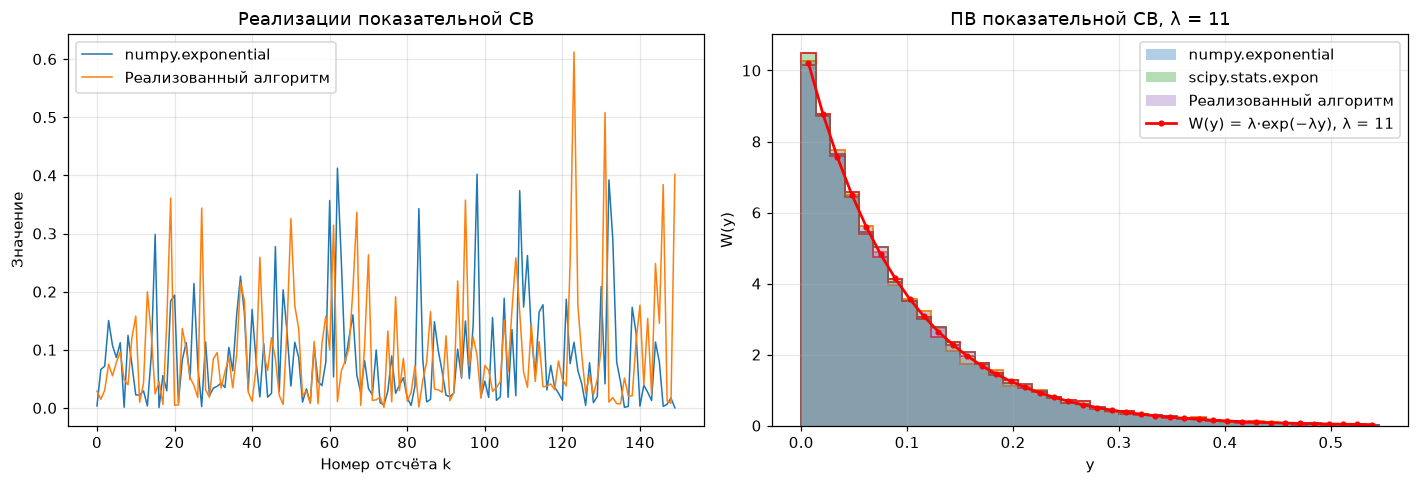

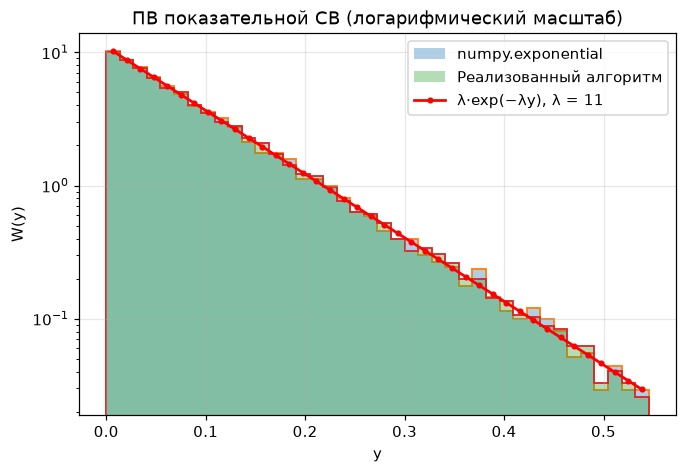

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
realization([y_exp_np, y_exp_custom], ['numpy.exponential', 'Реализованный алгоритм'], limit=150,
            title='Реализации показательной СВ', ax=axs[0])
edges_e = np.linspace(0, 6 / lambda_param, n_bins + 1)
pdf_compare([y_exp_np, y_exp_sp, y_exp_custom],
            ['numpy.exponential', 'scipy.stats.expon', 'Реализованный алгоритм'], edges_e,
            pdf=lambda y: stats.expon.pdf(y, scale=1 / lambda_param),
            pdf_label=f'W(y) = λ·exp(−λy), λ = {lambda_param}',
            title=f'ПВ показательной СВ, λ = {lambda_param}',
            xlabel='y', ylabel='W(y)', ax=axs[1])
plt.tight_layout()

fig, ax = plt.subplots(figsize=(7, 4.5))
pdf_compare([y_exp_np, y_exp_custom], ['numpy.exponential', 'Реализованный алгоритм'], edges_e,
            pdf=lambda y: stats.expon.pdf(y, scale=1 / lambda_param),
            pdf_label=f'λ·exp(−λy), λ = {lambda_param}',
            title='ПВ показательной СВ (логарифмический масштаб)', xlabel='y', ylabel='W(y)', ax=ax)
ax.set_yscale('log')

ks = stats.kstest(y_exp_custom, lambda v: stats.expon.cdf(v, scale=1 / lambda_param))
print(f'Критерий Колмогорова — Смирнова для реализованного алгоритма: D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}')

## Выводы

1. **Что сделано.** Реализован линейный конгруэнтный генератор равномерной СВ на $[0;1)$. Его гистограмма совпадает с библиотечной `numpy.uniform` и с идеальной плотностью $W(x)=1$. На примере генератора с малыми параметрами ($M = 32$) показано, что последовательность периодична: период не превышает $M$. Поэтому на практике берут $M = 2^{31}$ и больше.
2. Из равномерных СВ нелинейными преобразованиями получены релеевская СВ $r=\sqrt{-2\ln u_1}$ и арксинусная $s=\sin 2\pi u_2$. Их произведение после масштабирования, $y=\sigma r s+\mu$, даёт нормальную СВ $N(11, 2)$. Оценки среднего и дисперсии совпадают с теоретическими (11 и 4) с точностью до статистической погрешности. Гистограммы реализованного алгоритма и `numpy.normal` практически совпадают между собой и с гауссовой плотностью.
3. **Вариант 3.** Из двух независимых нормальных СВ $x_{1,2}\sim N(0, 2)$ преобразованием $y=(x_1^2+x_2^2)/(2\sigma^2\lambda)$ получена показательная СВ с $\lambda=11$. Гистограммы реализованного алгоритма, `numpy.random.exponential` и `scipy.stats.expon` совпадают с $W(y)=\lambda e^{-\lambda y}$. На логарифмическом масштабе плотность — прямая с наклоном $-\lambda$ во всём диапазоне, расхождения есть только в «хвосте», где в интервалы попадает мало значений.
4. **Анализ гистограмм.** Отклонения гистограмм от аналитических кривых случайны. Их относительная величина растёт там, где мало отсчётов: в хвостах нормального и показательного законов и около $|s|\to1$ у арксинусного, где плотность стремится к бесконечности, а конечный интервал гистограммы её усредняет. С ростом объёма выборки $N$ среднеквадратичное отклонение оценки в интервале убывает примерно как $1/\sqrt{N}$.
5. **Пример из радиоэлектроники.** Показательное распределение имеет мгновенная мощность (квадрат огибающей) узкополосного гауссовского шума на выходе приёмника: квадратурные составляющие шума $x_1, x_2$ — независимые нормальные СВ, огибающая $\sqrt{x_1^2+x_2^2}$ распределена по Рэлею, мощность $x_1^2+x_2^2$ — по показательному закону. Так же распределена интенсивность спекл-картины (лазерные спеклы) и мощность сигнала в канале с релеевскими замираниями.
6. **Нормировка гистограмм.** Сначала подсчитано число попаданий $n_k$ в каждый интервал. Затем каждое значение поделено на объём выборки $N$, что даёт относительную частоту, то есть оценку вероятности попадания в интервал. После этого оно поделено на ширину интервала $\Delta x$, что даёт оценку плотности вероятности. В результате площадь гистограммы равна 1, и её можно сравнивать с аналитической $W(x)$, вычисленной в серединах интервалов.